In [15]:
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)

In [23]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.seterr(divide='ignore', invalid='ignore')

def prepross(df_input):
    df_input.columns = df_input.columns.str.strip()

    categorical = ['university', 'degree_level', 'degree_major', 'cgpa', 'residential_status']
    df_encoded = pd.get_dummies(df_input[categorical])

    stress_metrics = ['academic_pressure', 'academic_workload', 'financial_concerns',
                      'social_relationships', 'depression', 'anxiety', 'isolation', 'future_insecurity']
    for col in stress_metrics:
        if col in df_input.columns:
            df_encoded[f'{col}_High'] = df_input[col] >= 4

    if 'stress_relief_activities' in df_input.columns:
        stress_activities = df_input['stress_relief_activities'].str.get_dummies(sep=', ')
        df_encoded = pd.concat([df_encoded, stress_activities], axis=1)
    return df_encoded.astype(bool)

df = pd.read_csv("MentalHealthSurvey.csv")
df_encoded = prepross(df)
df_encoded.head(10)

,university_COMSATS,university_FAST,university_KUST,university_NUST,university_PU,university_UET,university_UMT,university_UOL,university_VU,degree_level_Postgraduate,...,isolation_High,future_insecurity_High,Creative Outlets,Nothing,Online Entertainment,Outdoor Activities,Religious Activities,Sleep,Social Connections,Sports and Fitness
0,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,True,False,True,False,True,False
1,False,False,False,False,False,True,False,False,False,True,...,False,True,False,False,True,False,False,False,False,False
2,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,True,False,False,True
3,False,False,False,False,False,True,False,False,False,False,...,True,False,False,False,True,False,False,False,False,False
4,False,False,False,False,False,True,False,False,False,False,...,True,True,False,False,True,False,False,False,False,False
5,False,False,False,False,False,True,False,False,False,False,...,True,True,False,False,True,False,True,False,True,False
6,False,False,False,False,True,False,False,False,False,True,...,True,True,False,False,True,False,False,False,True,False
7,False,False,False,False,True,False,False,False,False,False,...,False,True,False,False,True,False,True,False,True,False
8,True,False,False,False,False,False,False,False,False,False,...,False,True,False,False,True,True,True,False,True,False
9,True,False,False,False,False,False,False,False,False,False,...,True,True,False,False,False,False,False,False,False,True


In [28]:
# the three groups
df_combined = prepross(df)
df_female = prepross(df[df['gender'] == 'Female'])
df_male = prepross(df[df['gender'] == 'Male'])


def generate_baseline_rules(df_encoded, stream_name):

    # Find itemsets that occur in at least 20% of observations
    freq_itemsets = apriori(
        df_encoded,
        min_support=0.20,
        use_colnames=True)

    # Keep rules with at least 60% confidence
    rules = association_rules(
        freq_itemsets,
        metric="confidence",
        min_threshold=0.60)

    # Mental-health outcomes
    target_outcomes = [
        'depression_High',
        'academic_pressure_High',
        'anxiety_High',
        'isolation_High']

    # Keep rules where the consequent is exactly
    # ONE mental-health outcome
    filtered_rules = rules[
        rules['consequents'].apply(
            lambda x:
                len(x) == 1
                and next(iter(x)) in target_outcomes)]

    # Don't allow another mental-health variable
    # to appear in the antecedent
    filtered_rules = filtered_rules[
        filtered_rules['antecedents'].apply(
            lambda x:
                not any(
                    item in x
                    for item in target_outcomes))]

    # Sort strongest associations by lift
    sorted_rules = filtered_rules.sort_values(
        by="lift",
        ascending=False)
    print(f"\nTOP RULES FOR: {stream_name.upper()}")

    if sorted_rules.empty:
        print("No rules met the thresholds for this slice.")

    else:
        print(sorted_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(8).to_string())
    return sorted_rules


rules_combined = generate_baseline_rules(
    df_combined,
    "Combined Data (Both Genders)")

rules_female = generate_baseline_rules(
    df_female,
    "Females Only")

rules_male = generate_baseline_rules(
    df_male,
    "Males Only")



TOP RULES FOR: COMBINED DATA (BOTH GENDERS)
                                                                             antecedents        consequents   support  confidence      lift
874         (degree_level_Undergraduate, academic_workload_High, future_insecurity_High)  (depression_High)  0.218391    0.791667  1.766026
446                                     (academic_workload_High, future_insecurity_High)  (depression_High)  0.229885    0.769231  1.715976
281                                 (degree_level_Undergraduate, future_insecurity_High)  (depression_High)  0.264368    0.741935  1.655087
684  (degree_level_Undergraduate, future_insecurity_High, residential_status_Off-Campus)  (depression_High)  0.229885    0.740741  1.652422
892         (degree_level_Undergraduate, academic_workload_High, future_insecurity_High)     (anxiety_High)  0.206897    0.750000  1.631250
85                                                              (future_insecurity_High)  (depression_High)  0.2758

Support
- 0.01% to 10%

Confidence
- 50% to 70%+

Lift
- Lift = 1.0 → no association beyond the baseline
- Lift > 1.0 → positive association; the outcome occurs more often than expected
- Lift < 1.0 → negative association; the outcome occurs less often than expected
- The farther above 1, the stronger the positive association

Explanation of results:

- Both genders: For the combined sample of male and female students, the strongest association rules were primarily related to f**uture insecurity, high academic workload, undergraduate status, and depression or anxiety.** The rule with the highest lift was undergraduate + high academic workload + high future insecurity → high depression, with a support of 21.84%, confidence of 79.17%, and lift of 1.77. This means that **21.84% of all students had all of these characteristics, and among students meeting the three conditions in the antecedent, 79.17% also had high depression.** The lift of 1.77 indicates that high depression occurred about 1.77 times as often as would be expected based on its overall frequency when those characteristics occurred together. A similar pattern appeared for high academic workload + high future insecurity → high depression, which had 22.99% support, 76.92% confidence, and a 1.72 lift. The rule high future insecurity → high depression occurred in 27.59% of the sample, had 72.73% confidence, and a 1.62 lift, showing that future insecurity was repeatedly associated with high depression in the combined data. High future insecurity also appeared in rules predicting anxiety, suggesting that it was an important characteristic among the strongest associations identified in the combined sample. **These results show associations between these student characteristics and mental-health outcomes, but they do not establish that one factor causes another.**

- Females: For female students, the strongest rules were primarily associated with **high anxiety and high isolation.** Several rules had 20.83% support and 100% confidence, meaning that approximately 20.83% of the female sample met the conditions in the antecedent and, within those cases, **100% also had high anxiety.** For example, high future insecurity + undergraduate status + CGPA between 3.0–3.5 + high academic workload → high anxiety had a lift of 1.71. The same support, confidence, and lift appeared for several other combinations, including CGPA 3.0–3.5 + high future insecurity → high anxiety and CGPA 3.5–4.0 + off-campus residence → high anxiety. A lift of 1.71 means that high anxiety occurred about 1.71 times the expected rate among students with those antecedent characteristics. Other rules involving high financial concerns + high academic workload → high isolation had 71.43% confidence and a 1.56 lift, **meaning that about 71% of female students meeting those conditions also had high isolation,** and the association was higher than the baseline occurrence of isolation. **However, the female subgroup contains only 24 students, so the 20.83% support corresponds to approximately 5 students. Therefore, the 100% confidence results should be interpreted cautiously because they are based on a relatively small number of observations.**

- Males: For male students, the strongest associations were primarily related to **high future insecurity and high depression, anxiety, and isolation.** The rule undergraduate + high future insecurity → high depression had 22.22% support, 66.67% confidence, and a 1.83 lift, meaning that **22.22% of male students had both characteristics in the antecedent and that two-thirds of those students also had high depression.** The lift of 1.83 indicates that high depression occurred about 1.83 times the expected rate among students with those characteristics. The simpler rule high future insecurity → high depression had 23.81% support, 65.22% confidence, and a 1.79 lift, showing that high future insecurity was also associated with high depression when considered by itself. High future insecurity was similarly associated with anxiety: undergraduate + high future insecurity + off-campus residence → high anxiety had 20.63% support, 72.22% confidence, and a 1.75 lift. In addition, the rules involving high future insecurity and off-campus residence were associated with anxiety, while high future insecurity was also associated with high isolation. **Overall, the male results show that high future insecurity repeatedly appeared in the strongest rules across multiple mental-health outcomes, although these results represent associations rather than evidence that future insecurity causes depression, anxiety, or isolation.**

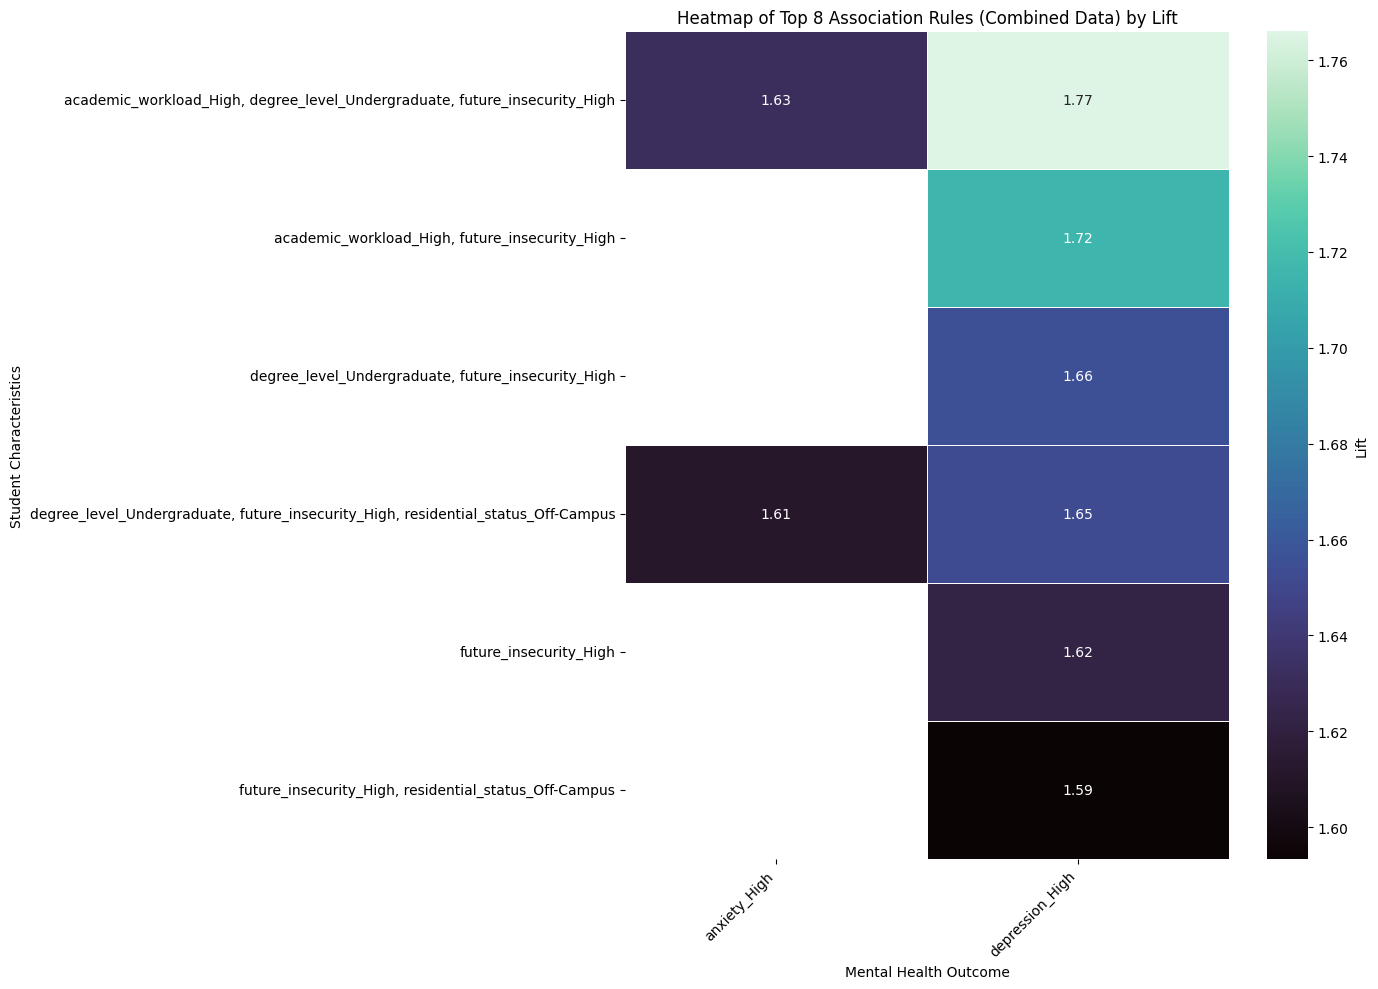

In [29]:
# Using the top 8 rules to visualize
N = 8
top_rules = rules_combined.head(N).copy()

# Convert antecedents and consequents to readable strings
top_rules['antecedents_str'] = (
    top_rules['antecedents']
    .apply(lambda x: ', '.join(sorted(list(x)))))

top_rules['consequents_str'] = (
    top_rules['consequents']
    .apply(lambda x: ', '.join(sorted(list(x)))))

# Rows = antecedents
# Columns = consequents
# Values = lift
heatmap_data_combined = top_rules.pivot_table(
    index='antecedents_str',
    columns='consequents_str',
    values='lift')


# Create heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(heatmap_data_combined, annot=True, cmap='mako', fmt=".2f", linewidths=0.5, cbar_kws={'label': 'Lift'})
plt.title(f'Heatmap of Top {N} Association Rules ', f'(Both genders) by Lift')
plt.xlabel('Mental Health Outcome')
plt.ylabel('Student Characteristics')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

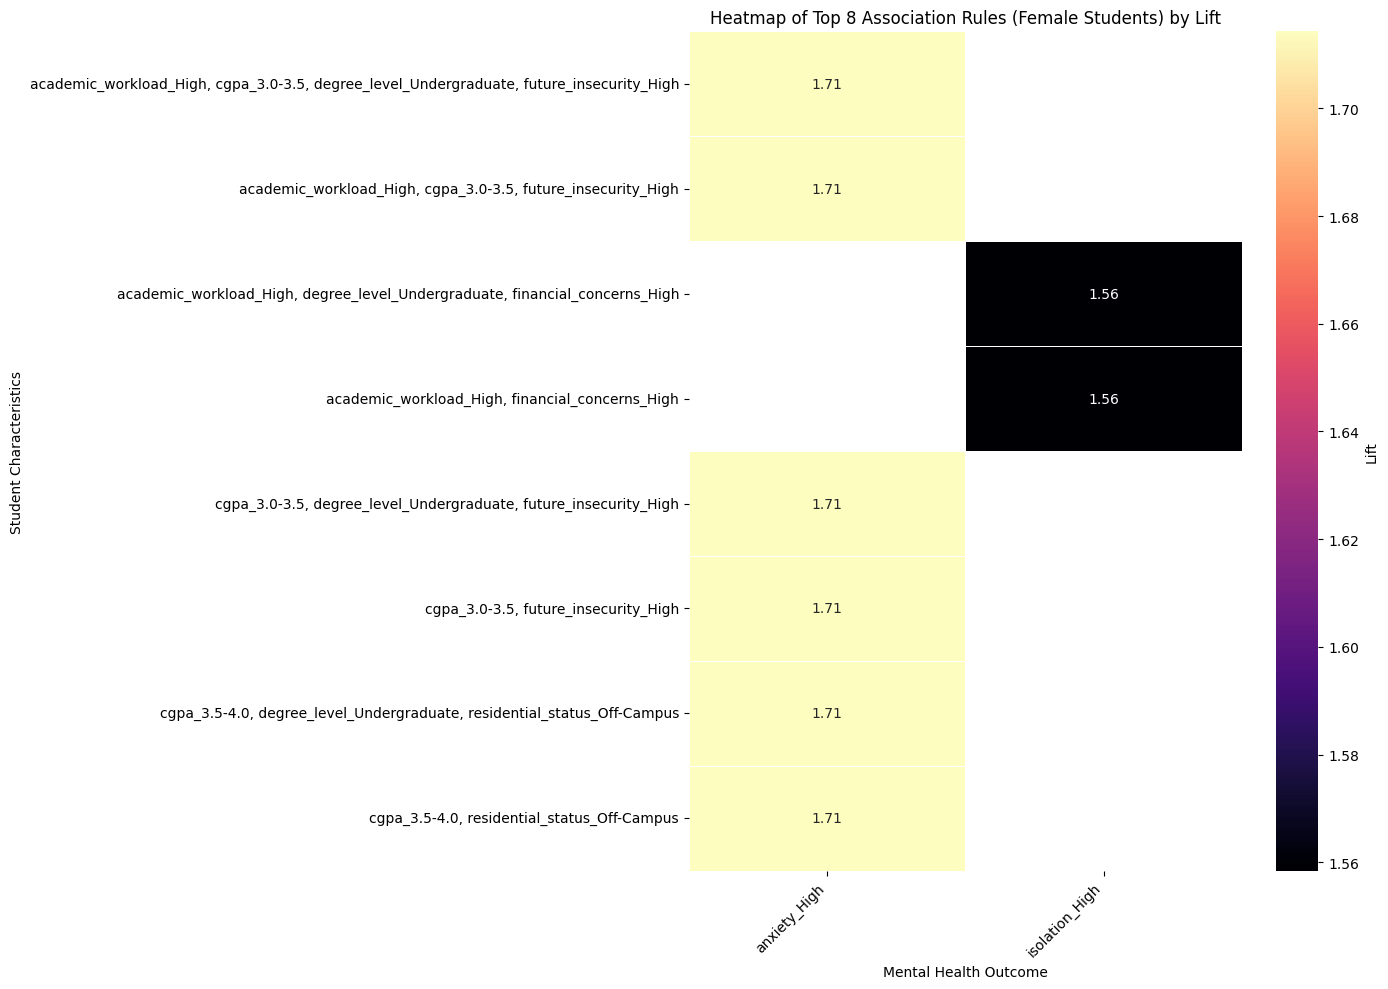

In [36]:
N = 8
top_female_rules = rules_female.head(N).copy()

top_female_rules['antecedents_str'] = (
    top_female_rules['antecedents']
    .apply(lambda x: ', '.join(sorted(list(x)))))

top_female_rules['consequents_str'] = (
    top_female_rules['consequents']
    .apply(lambda x: ', '.join(sorted(list(x)))))

heatmap_data_female = top_female_rules.pivot_table(
    index='antecedents_str',
    columns='consequents_str',
    values='lift')

plt.figure(figsize=(14, 10))
sns.heatmap(heatmap_data_female, annot=True, cmap='magma', fmt=".2f", linewidths=0.5, cbar_kws={'label': 'Lift'})
plt.title(f'Heatmap of Top {N} Association Rules (Female Students) by Lift')
plt.xlabel('Mental Health Outcome')
plt.ylabel('Student Characteristics')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

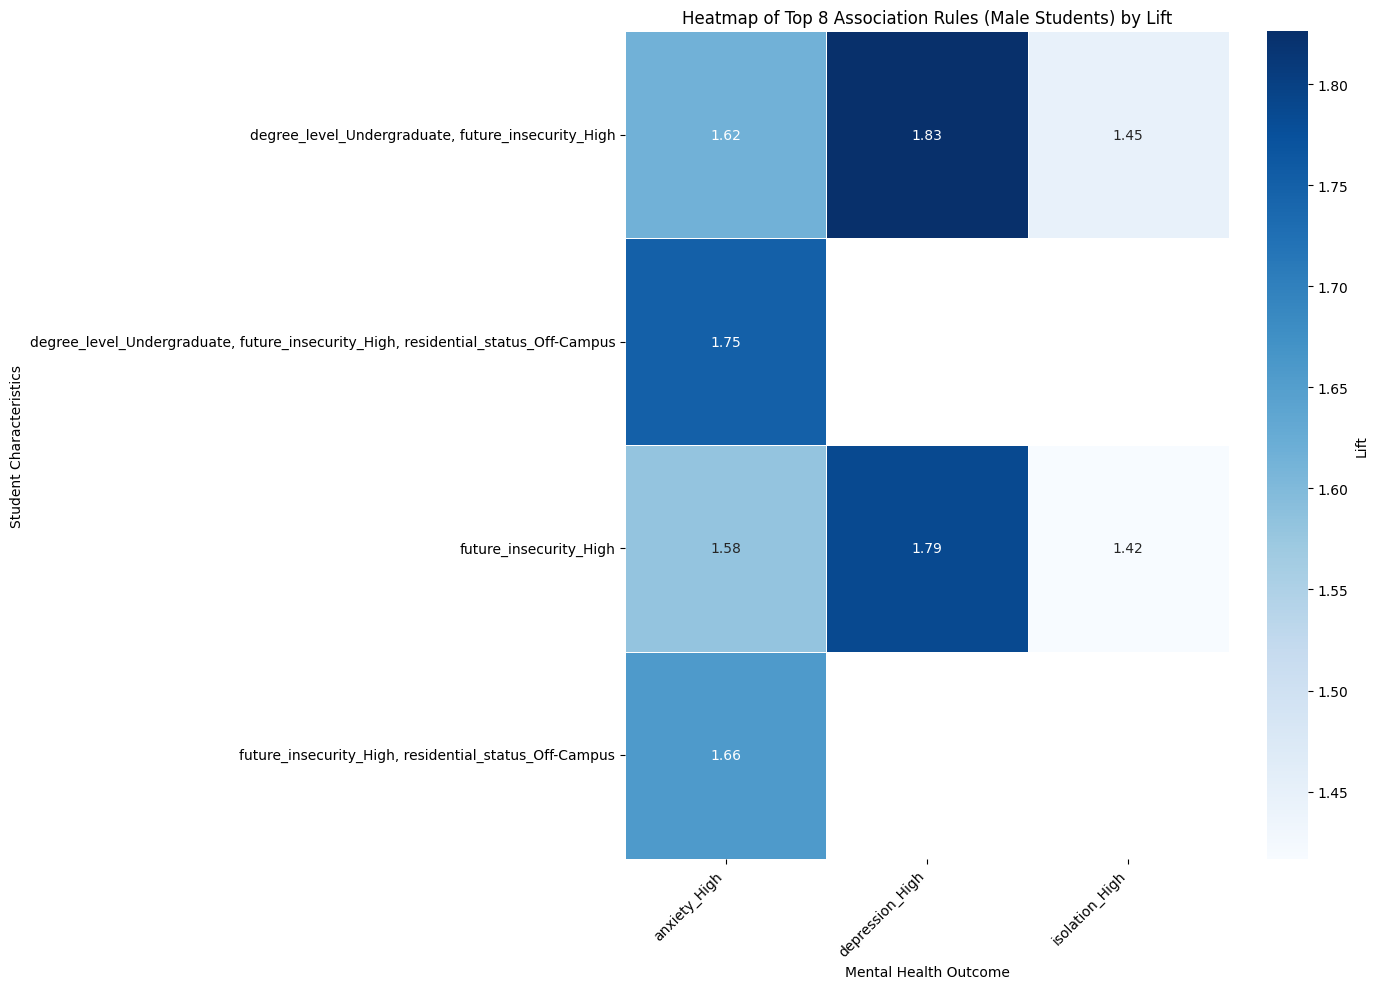

In [37]:
N = 8
top_male_rules = rules_male.head(N).copy()

top_male_rules['antecedents_str'] = (
    top_male_rules['antecedents']
    .apply(lambda x: ', '.join(sorted(list(x)))))

top_male_rules['consequents_str'] = (
    top_male_rules['consequents']
    .apply(lambda x: ', '.join(sorted(list(x)))))

heatmap_data_male = top_male_rules.pivot_table(
    index='antecedents_str',
    columns='consequents_str',
    values='lift')

plt.figure(figsize=(14, 10))
sns.heatmap(heatmap_data_male, annot=True, cmap='Blues', fmt=".2f", linewidths=0.5, cbar_kws={'label': 'Lift'})
plt.title(f'Heatmap of Top {N} Association Rules (Male Students) by Lift')
plt.xlabel('Mental Health Outcome')
plt.ylabel('Student Characteristics')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()